# Practice 15 — Transformer for Time Series

**Goal:** let every day of a window look at every other day (attention) and predict the next day's closing index with a Transformer encoder.

| Step | What it produces |
|:---|:---|
| Series, windows, split | KOSPI daily quotes → five-day windows → chronological train / validation / test, scaled on train |
| Attention by hand | scores, softmax weights and the context vector on one window, then with projections |
| Positional encoding | the sine–cosine table that tells attention which day is which |
| `train` / `evaluate` | the epoch loop and the no-grad pass |
| Transformer encoder | embedding + positional encoding → `nn.TransformerEncoder` → linear readout |
| RNN, LSTM | the recurrent models under the same settings |
| Comparison | learning curves, predictions, RMSE, the learned attention map |

---
## Step 0. Imports and Setup

In [1]:
import os
import math
import urllib.request

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


---
## Step 1. The Series

- One row per trading day

| Column | Use |
|:---|:---|
| `Open`, `High`, `Low`, `Volume` | model input |
| `Close` | prediction target |
| `Date`, `Adj Close` | not used |

In [2]:
DATA_PATH = './data/kospi.csv'
DATA_URL = 'https://raw.githubusercontent.com/jongmoonha/AI-ME-Practice/main/data/kospi.csv'

if not os.path.exists(DATA_PATH):
    os.makedirs('./data', exist_ok=True)
    print('downloading kospi.csv ...')
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)

print('df', df.shape)

first_date = df['Date'].iloc[0]
last_date = df['Date'].iloc[-1]
print(f'trading days from {first_date} to {last_date}')

df (431, 7)
trading days from 2019-01-30 to 2020-10-30


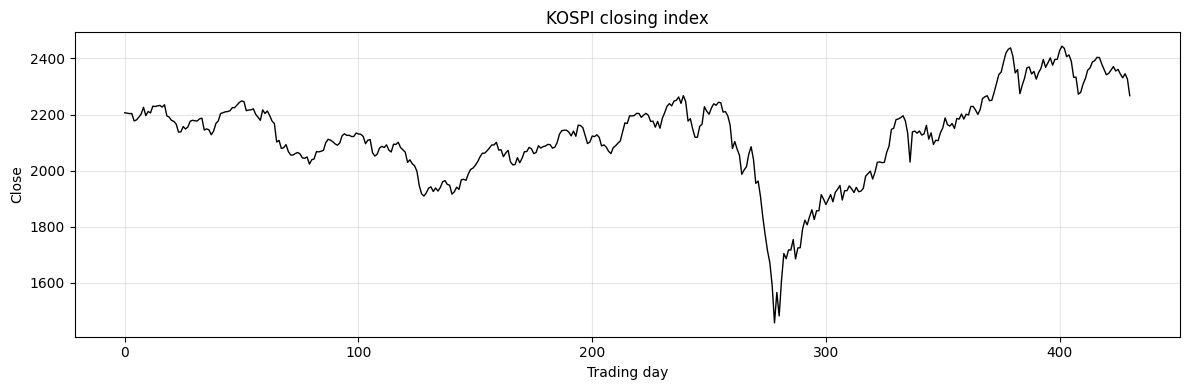

In [3]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))

ax.plot(df['Close'].values, 'k-', linewidth=1)
ax.set_xlabel('Trading day')
ax.set_ylabel('Close')
ax.set_title('KOSPI closing index')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
df.head(10)

,Date,Open,High,Low,Close,Adj Close,Volume
0,2019-01-30,2183.489990,2206.199951,2177.879883,2206.199951,2206.199951,480400
1,2019-01-31,2222.879883,2222.879883,2201.219971,2204.850098,2204.850098,545200
2,2019-02-01,2211.929932,2218.780029,2201.409912,2203.459961,2203.459961,479400
3,2019-02-07,2215.770020,2215.790039,2196.770020,2203.419922,2203.419922,427800
4,2019-02-08,2192.010010,2192.479980,2171.959961,2177.050049,2177.050049,391000
5,2019-02-11,2180.540039,2181.580078,2167.360107,2180.729980,2180.729980,406100
6,2019-02-12,2182.709961,2195.050049,2178.590088,2190.469971,2190.469971,429900
7,2019-02-13,2200.000000,2203.709961,2194.750000,2201.479980,2201.479980,422000
8,2019-02-14,2195.919922,2225.850098,2186.090088,2225.850098,2225.850098,573400
9,2019-02-15,2210.939941,2210.939941,2187.709961,2196.090088,2196.090088,400600


---
## Step 2. Sliding Windows

- $T$ days in → the next day's `Close` out

| Tensor | Shape | Meaning |
|:---|:---|:---|
| `X_seq` | `(N, T, d)` | $N$ windows of $T$ days, $d$ features per day |
| `y_seq` | `(N, 1)` | the `Close` of the day after each window |

- $T = 5$, 431 days → $N = 431 - 5 = 426$ windows

In [5]:
sequence_length = 5

X_all = df[['Open', 'High', 'Low', 'Volume']].values.astype(np.float32)
y_all = df[['Close']].values


def to_sequences(X, y, sequence_length):
    # window i covers days i .. i+sequence_length-1 and targets the Close of day i+sequence_length
    X_windows = []
    y_targets = []
    for i in range(len(X) - sequence_length):
        X_windows.append(X[i:i + sequence_length])
        y_targets.append(y[i + sequence_length])
    return np.array(X_windows), np.array(y_targets)


X_seq, y_seq = to_sequences(X_all, y_all, sequence_length)

print(f'X_seq {tuple(X_seq.shape)}   (N, T, d)')
print(f'y_seq {tuple(y_seq.shape)}   (N, 1)')

X_seq (426, 5, 4)   (N, T, d)


y_seq (426, 1)   (N, 1)


---
## Step 3. Chronological Split and Scaling

| Split | Windows | Share |
|:---|:---|:---|
| Train | 298 | 70% |
| Validation | 63 | 15% |
| Test | 65 | 15% |

- Neighbouring windows share four days → a shuffled split would put near-copies of every test window into training
- Time order → every validation and test window comes after every training window
- `StandardScaler` fitted on the training windows only → applied to all three splits

In [6]:
n_train = int(len(X_seq) * 0.70)
n_val = int(len(X_seq) * 0.15)

X_train, y_train = X_seq[:n_train], y_seq[:n_train]
X_val, y_val = X_seq[n_train:n_train + n_val], y_seq[n_train:n_train + n_val]
X_test, y_test = X_seq[n_train + n_val:], y_seq[n_train + n_val:]

close_train, close_val, close_test = y_train, y_val, y_test     # Close in index points, kept for the error later

input_size = X_seq.shape[2]

# the scaler takes a 2-D table, so the windows are flattened to one row per day and reshaped back
scaler_input = StandardScaler()
scaler_input.fit(X_train.reshape(-1, input_size))
X_train = scaler_input.transform(X_train.reshape(-1, input_size)).reshape(X_train.shape)
X_val = scaler_input.transform(X_val.reshape(-1, input_size)).reshape(X_val.shape)
X_test = scaler_input.transform(X_test.reshape(-1, input_size)).reshape(X_test.shape)

scaler_close = StandardScaler()
scaler_close.fit(y_train)
y_train = scaler_close.transform(y_train)
y_val = scaler_close.transform(y_val)
y_test = scaler_close.transform(y_test)

print(f'windows - train {len(X_train)}, val {len(X_val)}, test {len(X_test)}')
print(f'Close on the training windows - mean {scaler_close.mean_[0]:.2f}, std {scaler_close.scale_[0]:.2f}')
close_train_max = close_train.max()
n_val_above = (close_val > close_train_max).sum()
n_test_above = (close_test > close_train_max).sum()
print(f'training maximum of Close: {close_train_max:.0f}')
print(f'validation windows above it: {n_val_above} of {len(close_val)}')
print(f'test windows above it: {n_test_above} of {len(close_test)}')

windows - train 298, val 63, test 65
Close on the training windows - mean 2077.65, std 140.46
training maximum of Close: 2267
validation windows above it: 0 of 63
test windows above it: 58 of 65


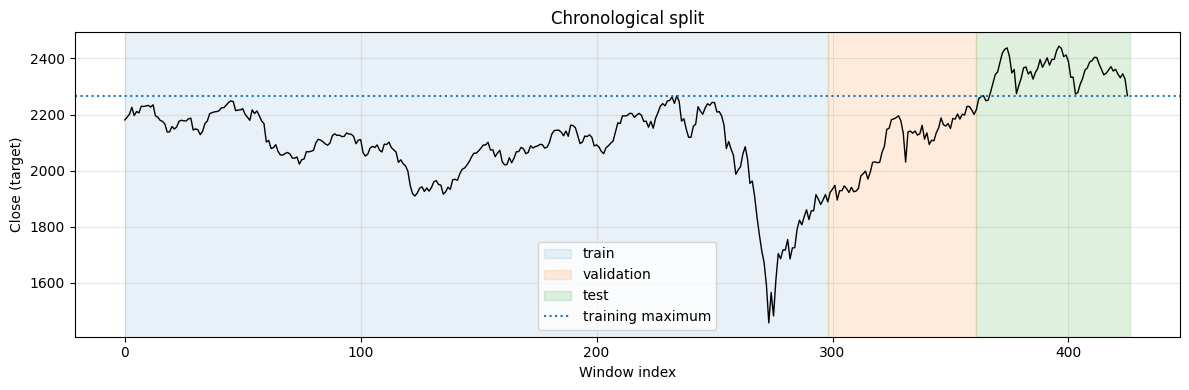

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(12, 4))

ax.plot(y_seq[:, 0], 'k-', linewidth=1)
ax.axvspan(0, n_train, color='tab:blue', alpha=0.10, label='train')
ax.axvspan(n_train, n_train + n_val, color='tab:orange', alpha=0.15, label='validation')
ax.axvspan(n_train + n_val, len(y_seq), color='tab:green', alpha=0.15, label='test')
ax.axhline(close_train_max, color='tab:blue', linestyle=':', label='training maximum')
ax.set_xlabel('Window index')
ax.set_ylabel('Close (target)')
ax.set_title('Chronological split')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- 58 of 65 test targets lie above the training maximum (2,267 points), 0 of 63 validation targets → the test split asks for extrapolation, validation does not

### Loaders

- `train_loader` shuffles the training windows within an epoch; the split itself stays chronological
- `all_loader` holds every window in time order → one pass predicts the whole series, cut into the splits with `n_train` and `n_val`

| Loader | Windows | `shuffle` | Used for |
|:---|:---|:---|:---|
| `train_loader` | train | `True` | the update loop |
| `val_loader` | validation | `False` | monitoring after each epoch |
| `all_loader` | train, validation, test | `False` | predictions in time order, read once at the end |

In [8]:
batch_size = 20

X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train)
X_val_tensor = torch.FloatTensor(X_val)
y_val_tensor = torch.FloatTensor(y_val)
X_seq_tensor = torch.FloatTensor(np.concatenate([X_train, X_val, X_test]))      # every window, standardized, in time order
y_seq_tensor = torch.FloatTensor(np.concatenate([y_train, y_val, y_test]))

train_set = TensorDataset(X_train_tensor, y_train_tensor)
val_set = TensorDataset(X_val_tensor, y_val_tensor)
all_set = TensorDataset(X_seq_tensor, y_seq_tensor)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
all_loader = DataLoader(all_set, batch_size=batch_size, shuffle=False)

print(f'batches per epoch - train {len(train_loader)}, val {len(val_loader)}, all {len(all_loader)}')

X_batch, y_batch = next(iter(train_loader))
print(f'one batch - X {tuple(X_batch.shape)}, y {tuple(y_batch.shape)}')

batches per epoch - train 15, val 4, all 22
one batch - X (20, 5, 4), y (20, 1)


---
## Step 4. Attention on One Window

$$e_j = \mathbf{q}^\top \mathbf{h}_j,
\qquad \alpha_j = \frac{\exp(e_j)}{\sum_k \exp(e_k)},
\qquad \mathbf{c} = \sum_j \alpha_j \mathbf{h}_j$$

- A recurrent readout sees only the last state; attention looks at every day of the window
- $\mathbf{h}_j$ → day $j$ of the window (four standardized features); $\mathbf{q}$ → the query, here the last day (the deck's $h_t$ at the last step, so $t$ is dropped)
- No parameters yet → a plain dot product

| Symbol | Code |
|:---|:---|
| $\mathbf{q}$ | `query` |
| $e$ | `score` |
| $\alpha$ | `alpha` |
| $\mathbf{c}$ | `context` |

In [9]:
X_window = X_train_tensor[0]            # one window, (T, d) = (5, 4), standardized
query = X_window[-1]                    # the last day asks which days matter

score = X_window @ query                # e_j = q . h_j, one number per day
alpha = torch.softmax(score, dim=0)     # attention weights, they sum to 1
context = alpha @ X_window              # c = sum_j alpha_j h_j, one vector of d features

print('score   :', score.numpy().round(2))
print('alpha   :', alpha.numpy().round(2), '  sum', round(alpha.sum().item(), 2))
print('context :', context.numpy().round(2))

score   : [1.99 2.19 2.34 2.51 2.26]
alpha   : [0.15 0.18 0.21 0.25 0.2 ]   sum 1.0
context : [ 0.9   0.89  0.85 -0.41]


- The weights stay between 0.15 and 0.25: the five standardized days of this window are alike, so no day stands out; the context vector is their weighted average
- Day 4 scores highest (2.51), above the query's own day 5 (2.26) → a dot product also grows with the norm of $\mathbf{h}_j$, not only with its direction

### With Projections

$$Q = H W_Q, \qquad K = H W_K, \qquad V = H W_V,
\qquad \mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V$$

- $H$ → the window as a `(T, d)` matrix, one day per row (`X_window` here; $H = E + P$ from Step 5 on)
- $W_Q$, $W_K$, $W_V$ → `(d, d_k)` projections; the deck's $K = W_K h_j$ acts on one day as a column, with days as rows it is $H W_K$
- Every day is a query at once (self-attention) → `score` and `alpha` become `(T, T)`, row = asking day, column = day looked at

In [10]:
d_k = 4                                 # the width of one head in Step 7 (d_model / nhead)

torch.manual_seed(42)
W_Q = torch.randn(input_size, d_k) / math.sqrt(input_size)      # random, scaled to keep Q, K, V around 1; Step 7 learns them
W_K = torch.randn(input_size, d_k) / math.sqrt(input_size)
W_V = torch.randn(input_size, d_k) / math.sqrt(input_size)

Q = X_window @ W_Q                      # (T, d_k), one query per day
K = X_window @ W_K                      # (T, d_k), one key per day
V = X_window @ W_V                      # (T, d_k), one value per day

score = Q @ K.T / math.sqrt(d_k)        # (T, T): row = query day, column = key day; sqrt(d_k) keeps the scores from growing with d_k
alpha = torch.softmax(score, dim=1)     # each row sums to 1
context = alpha @ V                     # (T, d_k): one context vector per query day

context_torch = F.scaled_dot_product_attention(Q, K, V)

print('by hand :')
print(context.numpy().round(3))
print('torch   :')
print(context_torch.numpy().round(3))

by hand :
[[-0.828 -0.624 -0.055  0.273]
 [-0.82  -0.633 -0.049  0.275]
 [-0.82  -0.632 -0.049  0.275]
 [-0.82  -0.634 -0.048  0.276]
 [-0.829 -0.625 -0.055  0.274]]
torch   :
[[-0.828 -0.624 -0.055  0.273]
 [-0.82  -0.633 -0.049  0.275]
 [-0.82  -0.632 -0.049  0.275]
 [-0.82  -0.634 -0.048  0.276]
 [-0.829 -0.625 -0.055  0.274]]


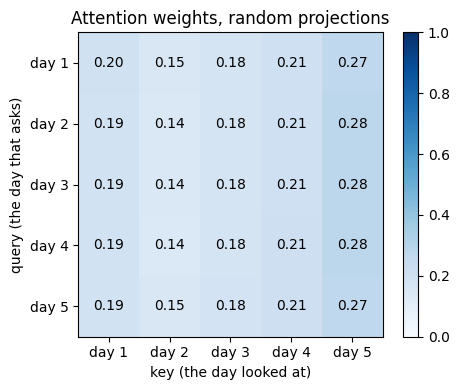

In [11]:
days = [f'day {t}' for t in range(1, sequence_length + 1)]

fig, ax = plt.subplots(1, 1, figsize=(5, 4))

image = ax.imshow(alpha.numpy(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(sequence_length))
ax.set_xticklabels(days)
ax.set_yticks(range(sequence_length))
ax.set_yticklabels(days)
ax.set_xlabel('key (the day looked at)')
ax.set_ylabel('query (the day that asks)')
ax.set_title('Attention weights, random projections')
for i in range(sequence_length):
    for j in range(sequence_length):
        ax.text(j, i, f'{alpha[i, j]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=ax)

plt.tight_layout()
plt.show()

- The two matrices agree → `F.scaled_dot_product_attention` is these three lines; each row of the map sums to 1
- Every row looks alike: the five days are alike and the projections are random; the learned map in Step 9 is the one to read

### Attention Does Not Know the Order

- Reverse the window (day 5 first) and run the same projections

In [12]:
X_reversed = X_window.flip(0)           # day 5 first, day 1 last

Q_reversed = X_reversed @ W_Q
K_reversed = X_reversed @ W_K
V_reversed = X_reversed @ W_V

context_reversed = F.scaled_dot_product_attention(Q_reversed, K_reversed, V_reversed)

print('day 5, original order :', context_torch[-1].numpy().round(3))
print('day 5, reversed order :', context_reversed[0].numpy().round(3))

day 5, original order : [-0.829 -0.625 -0.055  0.274]
day 5, reversed order : [-0.829 -0.625 -0.055  0.274]


- Same vector → each day's output is the same wherever the day sits, so a readout of the last row cannot know which day it got
- A model that predicts tomorrow must know which row is today

---
## Step 5. Positional Encoding

$$P_{pos,\,2i} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right),
\qquad P_{pos,\,2i+1} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right),
\qquad H = E + P$$

- $E$ → the embedding, Step 7's `nn.Linear` from the four features to `d_model = 8` numbers; $P$ has that width so attention sees the sum $H$ (the deck's $d$ is `d_model`)
- $pos$ → the position in the window (0 to $T - 1$), $i$ → the pair index of the columns
- Each column is a sine or cosine of a different period → every position gets its own vector; fixed numbers, not parameters

In [13]:
d_model = 8


def positional_encoding(sequence_length, d_model):
    # P[pos, 2i] = sin(pos / 10000^(2i / d_model)),  P[pos, 2i + 1] = cos(pos / 10000^(2i / d_model))
    P = torch.zeros(sequence_length, d_model)
    for pos in range(sequence_length):
        for i in range(d_model // 2):
            P[pos, 2 * i] = math.sin(pos / 10000 ** (2 * i / d_model))
            P[pos, 2 * i + 1] = math.cos(pos / 10000 ** (2 * i / d_model))
    return P


P = positional_encoding(sequence_length, d_model)

print('P', tuple(P.shape), '  (T, d_model)')
pd.DataFrame(P.numpy()).round(2)

P (5, 8)   (T, d_model)


,0,1,2,3,4,5,6,7
0,0.00,1.00,0.00,1.00,0.00,1.0,0.0,1.0
1,0.84,0.54,0.10,1.00,0.01,1.0,0.0,1.0
2,0.91,-0.42,0.20,0.98,0.02,1.0,0.0,1.0
3,0.14,-0.99,0.30,0.96,0.03,1.0,0.0,1.0
4,-0.76,-0.65,0.39,0.92,0.04,1.0,0.0,1.0


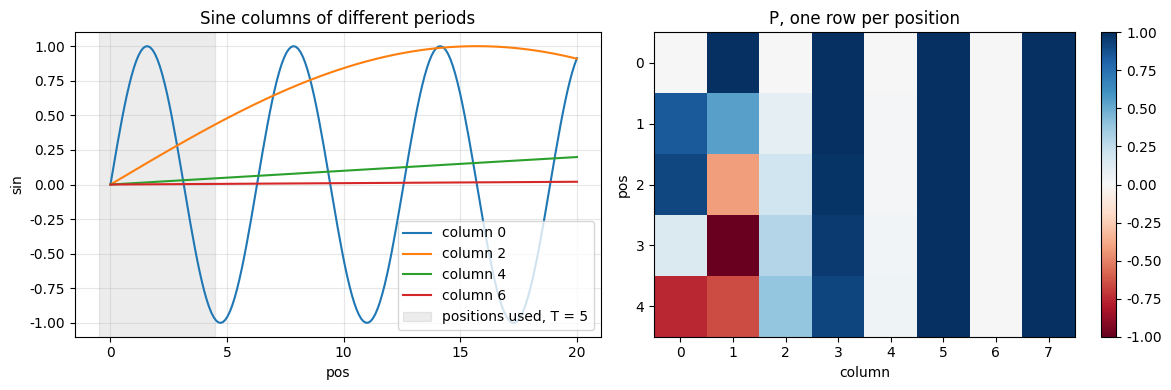

In [14]:
positions = np.linspace(0, 20, 200)     # pos as a continuous line, beyond T, to show each period

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i in range(d_model // 2):
    column = 2 * i
    axes[0].plot(positions, np.sin(positions / 10000 ** (2 * i / d_model)), label=f'column {column}')
axes[0].axvspan(-0.5, sequence_length - 0.5, color='gray', alpha=0.15, label='positions used, T = 5')
axes[0].set_xlabel('pos')
axes[0].set_ylabel('sin')
axes[0].set_title('Sine columns of different periods')
axes[0].legend()
axes[0].grid(alpha=0.3)

image = axes[1].imshow(P.numpy(), cmap='RdBu', vmin=-1, vmax=1, aspect='auto')
axes[1].set_xlabel('column')
axes[1].set_ylabel('pos')
axes[1].set_title('P, one row per position')
fig.colorbar(image, ax=axes[1])

plt.tight_layout()
plt.show()

- Column 0 changes fastest, column 6 barely moves over five positions → the first columns separate neighbouring days, the later ones carry the coarse position
- Each row of $P$ is unique → after $H = E + P$, the same quote on day 1 and on day 5 is no longer the same input

---
## Step 6. `train` and `evaluate`

| Function | Returns |
|:---|:---|
| `evaluate(model, loader, device)` | `(loss, y_pred)` |
| `train(model, train_loader, val_loader, optimizer, epochs, device)` | `(train_losses, val_losses)` |

- `loss` → mean of the per-batch MSEs on standardized targets, what the learning curves plot
- The error in index points comes from `y_pred` after training, with `scaler_close.inverse_transform`
- Shared settings below: $\rho$ (learning rate), epochs, layers, Adam, MSE

In [15]:
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.MSELoss()
    loss_sum = 0.0
    preds = []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            y_hat = model(X_batch)
            loss_sum += criterion(y_hat, y_batch).item()
            preds.append(y_hat.cpu())

    loss = loss_sum / len(loader)
    y_pred = torch.cat(preds).numpy()
    return loss, y_pred

In [16]:
def train(model, train_loader, val_loader, optimizer, epochs, device):
    criterion = nn.MSELoss()
    train_losses, val_losses = [], []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            y_hat = model(X_batch)
            loss = criterion(y_hat, y_batch)

            optimizer.zero_grad()                 # clear the accumulated gradients
            loss.backward()                       # autograd computes the gradients
            optimizer.step()                      # the optimizer updates the parameters

            loss_sum += loss.item()

        train_loss = loss_sum / len(train_loader)
        val_loss, _ = evaluate(model, val_loader, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if epoch % 50 == 0:
            print(f'  Epoch {epoch:3d}/{epochs}  train MSE={train_loss:.4f}  val MSE={val_loss:.4f}')
    return train_losses, val_losses

In [17]:
rho = 1e-3
epochs = 200
num_layers = 1

print(f'Sequence length : {sequence_length}')
print(f'Layers          : {num_layers}')
print(f'Batch size      : {batch_size}')
print(f'Learning rate   : {rho}')
print(f'Epochs          : {epochs}')
print('Optimizer       : Adam')
print('Loss            : MSELoss')

Sequence length : 5
Layers          : 1
Batch size      : 20
Learning rate   : 0.001
Epochs          : 200
Optimizer       : Adam
Loss            : MSELoss


---
## Step 7. Transformer Encoder

| Layer | Code | Meaning |
|:---|:---|:---|
| Embedding | `nn.Linear(input_size, d_model)` | $E$ |
| Positional encoding | `+ P` | `E + P` |
| Encoder layer × `num_layers` | `nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward)` | self-attention → add & norm → FFN → add & norm |
| Readout | `nn.Linear(d_model, 1)`, last position | $\hat{y}$ |

### Inside the Encoder Layer

- `nhead` = 2 sets of $W_Q$, $W_K$, $W_V$, each `d_model / nhead` = 4 wide (the $d_k$ of Step 4), concatenated and mixed by one linear layer
- add & norm → $x + \mathrm{sublayer}(x)$ (the residual connection), then `LayerNorm` over the `d_model` numbers; FFN → $\max(0, xW_1 + b_1)W_2 + b_2$ per position, `dim_feedforward` wide
- The last position has seen all five days → read out, as the recurrent models read their last state

In [18]:
nhead = 2
dim_feedforward = 16

In [19]:
class TransformerRegressor(nn.Module):
    def __init__(self, input_size, d_model, nhead, dim_feedforward, num_layers, sequence_length):
        super().__init__()
        self.embedding = nn.Linear(input_size, d_model)                                       # E
        self.register_buffer('P', positional_encoding(sequence_length, d_model))              # P: fixed, not a parameter, moves with .to(device)
        encoder_layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward, dropout=0.0,    # the default dropout 0.1 is off, as in the recurrent models
                                                   batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.embedding(x) + self.P                     # H = E + P, (N, T, d_model)
        h = self.encoder(h)                                # self-attention + FFN, num_layers times, same shape
        y_hat = self.fc(h[:, -1, :])                       # read the last position
        return y_hat

In [20]:
torch.manual_seed(42)
model_transformer = TransformerRegressor(input_size, d_model, nhead, dim_feedforward, num_layers, sequence_length).to(device)
optimizer_transformer = optim.Adam(model_transformer.parameters(), lr=rho)

n_params_transformer = sum(p.numel() for p in model_transformer.parameters())
print(f'parameters: {n_params_transformer}')

torch.manual_seed(42)   # train_loader shuffles from the same state for every model
train_mse_transformer, val_mse_transformer = train(model_transformer, train_loader, val_loader, optimizer_transformer, epochs, device)

parameters: 649


  Epoch  50/200  train MSE=0.0492  val MSE=0.0409


  Epoch 100/200  train MSE=0.0319  val MSE=0.0405


  Epoch 150/200  train MSE=0.0268  val MSE=0.0431


  Epoch 200/200  train MSE=0.0241  val MSE=0.0451


In [21]:
_, y_pred_transformer = evaluate(model_transformer, all_loader, device)
close_pred_transformer = scaler_close.inverse_transform(y_pred_transformer)      # every window, index points, time order

rmse_train_transformer = root_mean_squared_error(close_train, close_pred_transformer[:n_train])
rmse_val_transformer = root_mean_squared_error(close_val, close_pred_transformer[n_train:n_train + n_val])
rmse_test_transformer = root_mean_squared_error(close_test, close_pred_transformer[n_train + n_val:])

print(f'Transformer  RMSE (index points) - train {rmse_train_transformer:6.1f}, val {rmse_val_transformer:6.1f}, test {rmse_test_transformer:6.1f}')

Transformer  RMSE (index points) - train   20.6, val   33.3, test   97.4


---
## Step 8. RNN and LSTM under the Same Settings

- Same loaders, $\rho$, epochs, optimizer, loss and seeds, no dropout anywhere → only the layer between the input and the readout changes
- `hidden_size` plays the role of `d_model`; both read the state of the last day

| Model | Layer | State carried from day to day |
|:---|:---|:---|
| RNN | `nn.RNN` | $\mathbf{h}_t$ |
| LSTM | `nn.LSTM` | $\mathbf{h}_t$ and the cell state $\mathbf{C}_t$ |

### RNN

In [22]:
class RNNRegressor(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # h_0 = 0
        out, h_n = self.rnn(x, h0)      # out holds h_1 .. h_T for every window in the batch
        y_hat = self.fc(out[:, -1, :])  # the last time step only
        return y_hat

In [23]:
hidden_size = d_model       # the same width as the Transformer

torch.manual_seed(42)
model_rnn = RNNRegressor(input_size, hidden_size, num_layers).to(device)
optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=rho)

n_params_rnn = sum(p.numel() for p in model_rnn.parameters())
print(f'parameters: {n_params_rnn}')

torch.manual_seed(42)
train_mse_rnn, val_mse_rnn = train(model_rnn, train_loader, val_loader, optimizer_rnn, epochs, device)

parameters: 121


  Epoch  50/200  train MSE=0.0539  val MSE=0.0440


  Epoch 100/200  train MSE=0.0399  val MSE=0.0312


  Epoch 150/200  train MSE=0.0364  val MSE=0.0324


  Epoch 200/200  train MSE=0.0330  val MSE=0.0310


In [24]:
_, y_pred_rnn = evaluate(model_rnn, all_loader, device)
close_pred_rnn = scaler_close.inverse_transform(y_pred_rnn)

rmse_train_rnn = root_mean_squared_error(close_train, close_pred_rnn[:n_train])
rmse_val_rnn = root_mean_squared_error(close_val, close_pred_rnn[n_train:n_train + n_val])
rmse_test_rnn = root_mean_squared_error(close_test, close_pred_rnn[n_train + n_val:])

print(f'RNN   RMSE (index points) - train {rmse_train_rnn:6.1f}, val {rmse_val_rnn:6.1f}, test {rmse_test_rnn:6.1f}')

RNN   RMSE (index points) - train   25.2, val   27.7, test   63.8


### LSTM

In [25]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # h_0 = 0
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=x.device)   # C_0 = 0
        out, (h_n, c_n) = self.lstm(x, (h0, c0))   # out holds h_1 .. h_T, as in RNNRegressor
        y_hat = self.fc(out[:, -1, :])
        return y_hat

In [26]:
torch.manual_seed(42)
model_lstm = LSTMRegressor(input_size, hidden_size, num_layers).to(device)
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=rho)

n_params_lstm = sum(p.numel() for p in model_lstm.parameters())
print(f'parameters: {n_params_lstm}')

torch.manual_seed(42)
train_mse_lstm, val_mse_lstm = train(model_lstm, train_loader, val_loader, optimizer_lstm, epochs, device)

parameters: 457


  Epoch  50/200  train MSE=0.0571  val MSE=0.0808


  Epoch 100/200  train MSE=0.0414  val MSE=0.0534


  Epoch 150/200  train MSE=0.0344  val MSE=0.0608


  Epoch 200/200  train MSE=0.0287  val MSE=0.0706


In [27]:
_, y_pred_lstm = evaluate(model_lstm, all_loader, device)
close_pred_lstm = scaler_close.inverse_transform(y_pred_lstm)

rmse_train_lstm = root_mean_squared_error(close_train, close_pred_lstm[:n_train])
rmse_val_lstm = root_mean_squared_error(close_val, close_pred_lstm[n_train:n_train + n_val])
rmse_test_lstm = root_mean_squared_error(close_test, close_pred_lstm[n_train + n_val:])

print(f'LSTM  RMSE (index points) - train {rmse_train_lstm:6.1f}, val {rmse_val_lstm:6.1f}, test {rmse_test_lstm:6.1f}')

LSTM  RMSE (index points) - train   23.5, val   41.7, test   67.3


---
## Step 9. Comparison

| Item | Transformer | RNN | LSTM |
|:---|:---|:---|:---|
| Layer | encoder: self-attention + FFN | `nn.RNN` | `nn.LSTM` |
| Width, layers | `d_model` 8, `nhead` 2, `dim_feedforward` 16, 1 layer | `hidden_size` 8, 1 layer | same |
| Parameters | 649 | 121 | 457 |
| Readout | `nn.Linear(8, 1)` on the last position | `nn.Linear(8, 1)` on `out[:, -1, :]` | same |
| Order information | positional encoding | the recurrence itself | same |
| Data, split, scaling, loaders, $\rho$, epochs, optimizer, loss, seeds | shared | shared | shared |

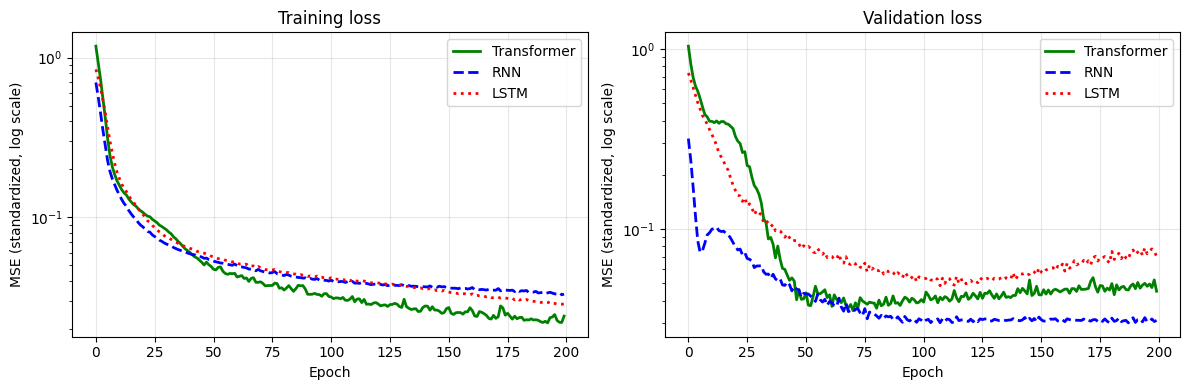

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_mse_transformer, 'g-', linewidth=2, label='Transformer')
axes[0].plot(train_mse_rnn, 'b--', linewidth=2, label='RNN')
axes[0].plot(train_mse_lstm, 'r:', linewidth=2, label='LSTM')
axes[0].set_yscale('log')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (standardized, log scale)')
axes[0].set_title('Training loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(val_mse_transformer, 'g-', linewidth=2, label='Transformer')
axes[1].plot(val_mse_rnn, 'b--', linewidth=2, label='RNN')
axes[1].plot(val_mse_lstm, 'r:', linewidth=2, label='LSTM')
axes[1].set_yscale('log')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE (standardized, log scale)')
axes[1].set_title('Validation loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Training loss: the Transformer ends lowest (0.024 vs RNN 0.033, LSTM 0.029); validation: it reaches 0.041 at epoch 50, 0.040 at 100 and climbs back to 0.045, the RNN settles near 0.031, the LSTM turns up after epoch 100
- 649 parameters on 298 windows → the encoder fits the training windows at the validation windows' expense; no early stopping here, the numbers below are the epoch-200 models

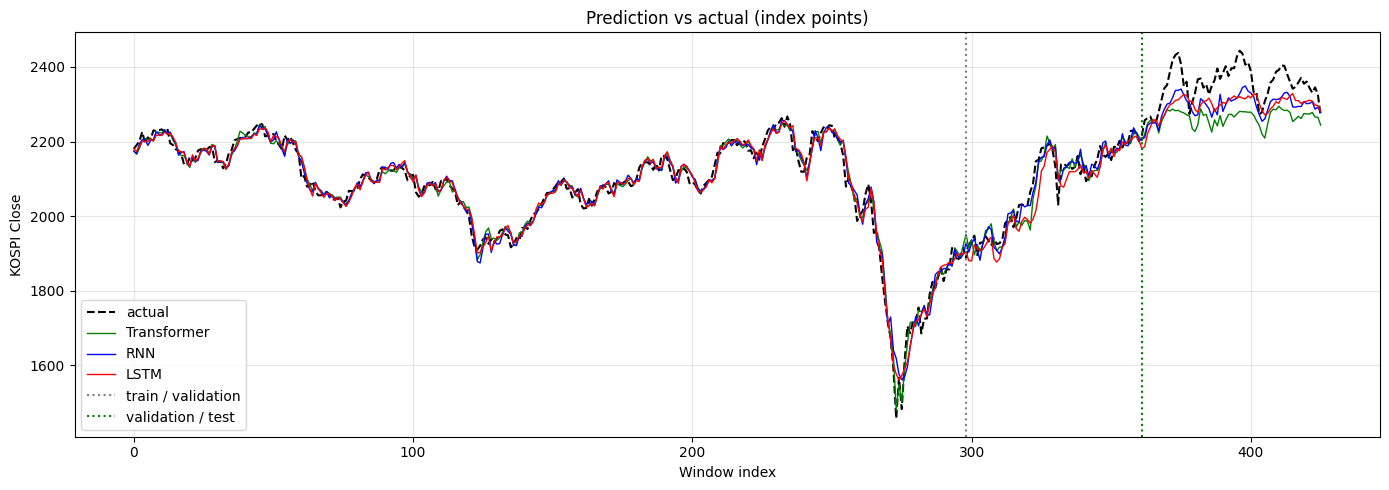

In [29]:
close_actual = np.concatenate([close_train, close_val, close_test])

fig, ax = plt.subplots(1, 1, figsize=(14, 5))

ax.plot(close_actual[:, 0], 'k--', linewidth=1.5, label='actual')
ax.plot(close_pred_transformer[:, 0], 'g-', linewidth=1, label='Transformer')
ax.plot(close_pred_rnn[:, 0], 'b-', linewidth=1, label='RNN')
ax.plot(close_pred_lstm[:, 0], 'r-', linewidth=1, label='LSTM')
ax.axvline(n_train, color='gray', linestyle=':', label='train / validation')
ax.axvline(n_train + n_val, color='green', linestyle=':', label='validation / test')
ax.set_xlabel('Window index')
ax.set_ylabel('KOSPI Close')
ax.set_title('Prediction vs actual (index points)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Inside the training range all three follow the series; in the test stretch all fall short of the peaks, the Transformer the most: the extrapolation counted in Step 3

In [30]:
pd.DataFrame([
    {'model': 'Transformer', 'parameters': n_params_transformer, 'train RMSE': rmse_train_transformer, 'val RMSE': rmse_val_transformer, 'test RMSE': rmse_test_transformer},
    {'model': 'RNN', 'parameters': n_params_rnn, 'train RMSE': rmse_train_rnn, 'val RMSE': rmse_val_rnn, 'test RMSE': rmse_test_rnn},
    {'model': 'LSTM', 'parameters': n_params_lstm, 'train RMSE': rmse_train_lstm, 'val RMSE': rmse_val_lstm, 'test RMSE': rmse_test_lstm},
]).round(1)

,model,parameters,train RMSE,val RMSE,test RMSE
0,Transformer,649,20.6,33.3,97.4
1,RNN,121,25.2,27.7,63.8
2,LSTM,457,23.5,41.7,67.3


- Validation, inside the fitted range → RNN 27.7, Transformer 33.3, LSTM 41.7 points: on 298 five-day windows the attention layer does not beat the simplest recurrence
- Test → 63.8, 97.4, 67.3, reported for completeness: it measures drift outside the fitted range, so model choice uses validation
- Layer type, positional encoding, FFN and parameter count all differ → one run cannot say which costs the Transformer; another seed or GPU moves the numbers by a few points

### The Attention Map the Model Learned

- The encoder layer's `self_attn` returns its weights when asked → `(N, T, T)` for the validation windows, averaged over the heads
- The map of Step 4 again, now with the learned $W_Q$, $W_K$, $W_V$ and averaged over the 63 validation windows

alpha_val (63, 5, 5)   (N_val, T, T)
last row, averaged over the validation windows: [0.24 0.22 0.18 0.18 0.19]


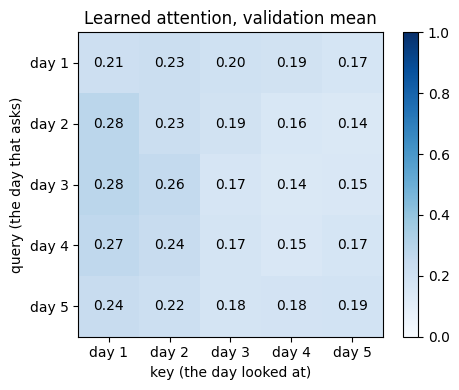

In [31]:
model_transformer.eval()
with torch.no_grad():
    h_val = model_transformer.embedding(X_val_tensor.to(device)) + model_transformer.P   # H = E + P
    _, alpha_val = model_transformer.encoder.layers[0].self_attn(h_val, h_val, h_val,                   # query, key, value all from H: self-attention
                                                                 need_weights=True, average_attn_weights=True)

alpha_val = alpha_val.cpu().numpy()
alpha_mean = alpha_val.mean(axis=0)

print('alpha_val', alpha_val.shape, '  (N_val, T, T)')
print('last row, averaged over the validation windows:', alpha_mean[-1].round(2))

fig, ax = plt.subplots(1, 1, figsize=(5, 4))

image = ax.imshow(alpha_mean, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(sequence_length))
ax.set_xticklabels(days)
ax.set_yticks(range(sequence_length))
ax.set_yticklabels(days)
ax.set_xlabel('key (the day looked at)')
ax.set_ylabel('query (the day that asks)')
ax.set_title('Learned attention, validation mean')
for i in range(sequence_length):
    for j in range(sequence_length):
        ax.text(j, i, f'{alpha_mean[i, j]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=ax)

plt.tight_layout()
plt.show()

- The last row spreads almost evenly (0.24, 0.22, 0.18, 0.18, 0.19), a little more on days 1 and 2 → the readout averages the window rather than singling out yesterday
- Five days at nearly the same level give attention little to choose between; Exercise 2 lengthens the window to 40 days
- With a long series the usual route is a pretrained Transformer: its blocks stay frozen and only a new embedding and readout are trained

### Optional — Without Positional Encoding

- Same model, the buffer $P$ set to zero → the last position keeps its own day, but the other four days become a set

In [32]:
torch.manual_seed(42)
model_no_position = TransformerRegressor(input_size, d_model, nhead, dim_feedforward, num_layers, sequence_length).to(device)
model_no_position.P.zero_()                             # P = 0, H = E
optimizer_no_position = optim.Adam(model_no_position.parameters(), lr=rho)

torch.manual_seed(42)
train_mse_no_position, val_mse_no_position = train(model_no_position, train_loader, val_loader, optimizer_no_position, epochs, device)

_, y_pred_no_position = evaluate(model_no_position, all_loader, device)
close_pred_no_position = scaler_close.inverse_transform(y_pred_no_position)

rmse_val_no_position = root_mean_squared_error(close_val, close_pred_no_position[n_train:n_train + n_val])
rmse_test_no_position = root_mean_squared_error(close_test, close_pred_no_position[n_train + n_val:])

print(f'Transformer, P = 0  RMSE (index points) - val {rmse_val_no_position:6.1f}, test {rmse_test_no_position:6.1f}')

  Epoch  50/200  train MSE=0.0461  val MSE=0.0486


  Epoch 100/200  train MSE=0.0328  val MSE=0.0454


  Epoch 150/200  train MSE=0.0280  val MSE=0.0526


  Epoch 200/200  train MSE=0.0252  val MSE=0.0494
Transformer, P = 0  RMSE (index points) - val   34.5, test  102.9


- Validation 34.5 points vs 33.3 with $P$ (test 102.9 vs 97.4) → without the order the encoder cannot tell yesterday from four days ago, and it does a little worse in this run; the gap moves with the seed

---
## Summary

- Attention is three lines: dot-product scores, a softmax over the days, a weighted sum of their values — with projections, `F.scaled_dot_product_attention`
- Attention alone is blind to order → $P$ is added to the embedding first
- On validation, in this run, the RNN (27.7 points) beats the Transformer (33.3) and the LSTM (41.7); the learned attention map averages the five days

---
## Exercises

1. `nhead = 4`, then `num_layers = 2` (all three classes read it) — retrain all three: do more heads or layers help on validation?
2. `sequence_length = 40`, rerun from Step 2 — which days does the last row of the attention map look at?
3. Read out `h.mean(dim=1)` instead of the last position — does the validation error change?
4. Add `Close` to the input columns, retrain — does yesterday's level change the test error?

In [33]:
# Write your code here